---
title: "Figures: The Diamond OLG Model"
execute:
  depends_on_env: [IC_EXEC_ENV]
---

Run this notebook in your browser, with nothing to install, in [JupyterLite](https://intertemporal-choice.github.io/lite/notebooks/index.html?path=OLGModel.ipynb); or open it in [Colab](https://colab.research.google.com/github/intertemporal-choice/intertemporal-choice.github.io/blob/main/content/consumption/OLGModel/OLGModel.ipynb) or [Binder](https://mybinder.org/v2/gh/intertemporal-choice/intertemporal-choice.github.io/main?labpath=content/consumption/OLGModel/OLGModel.ipynb).

In [the Diamond OLG model](https://intertemporal-choice.github.io/content/consumption/olgmodel), the young work, consume and save, and the old live on their savings, which are the next period's capital. With Cobb-Douglas production, $\mathrm{f}(k) = k^{\alpha}$, and logarithmic utility, capital per young worker follows

$$
k_{t+1} = \mathcal{Q} k_{t}^{\alpha}, \qquad \mathcal{Q} = \frac{(1-\alpha)\beta}{\Xi(1+\beta)},
$$

where $\Xi$ is the growth factor of the population, and converges to the steady state $\bar{k} = \mathcal{Q}^{1/(1-\alpha)}$. Steady-state consumption per worker, $\mathrm{f}(\bar{k}) - \xi \bar{k}$ with $\xi = \Xi - 1$, is highest at the golden rule $k^{**} = (\xi/\alpha)^{1/(\alpha-1)}$, where $\mathrm{f}^{\prime}(k^{**}) = \xi$; an economy with more capital than that is dynamically inefficient. A planner who discounts each generation by $\beth$ chooses $k^{*}$, where $1 + \mathrm{f}^{\prime}(k^{*}) = \Xi/\beth$. A period is a generation, here 30 years.

In [ ]:
# Run anywhere: install the book's package (it brings econ-ark, numpy and matplotlib) if it
# is missing. Inside the book's own environment this does nothing.
try:
    import intertemporal_choice
except ImportError:
    %pip install -q git+https://github.com/intertemporal-choice/intertemporal-choice.github.io

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from intertemporal_choice import olg, style

style.use_book_style()

## The model

The functions down to `k_planner` are the chapter's equations. The rest are the [Social Security chapter's](https://intertemporal-choice.github.io/content/consumption/socsecandkaccum) accumulation curve, with no population growth: as that chapter's figure draws it, with the interest factor held at its old value, and exactly, with the interest factor that next period's capital earns; and the new steady state on each.

In [ ]:
def wage(k, alpha):
    return (1 - alpha) * k**alpha


def interest_factor(k, alpha):
    return 1 + alpha * k ** (alpha - 1)  # R = 1 + f'(k), with no depreciation


def Q(alpha, beta, Xi):
    return (1 - alpha) * beta / (Xi * (1 + beta))


def k_next(k, alpha, beta, Xi):
    return Q(alpha, beta, Xi) * k**alpha


def k_bar(alpha, beta, Xi):
    return Q(alpha, beta, Xi) ** (1 / (1 - alpha))


def k_golden(alpha, xi):
    return (xi / alpha) ** (1 / (alpha - 1))  # where f'(k) = xi


def k_planner(alpha, Xi, beth):
    return ((Xi / beth - 1) / alpha) ** (1 / (alpha - 1))  # where 1 + f'(k) = Xi / beth


def k_next_payg(k, alpha, beta, z):
    """With contributions z from the young paid to the old, and the interest factor held at its old value."""
    R = interest_factor(k_bar(alpha, beta, 1.0), alpha)
    return Q(alpha, beta, 1.0) * k**alpha - z * (1 + R * beta) / (R * (1 + beta))


def k_next_payg_exact(k, alpha, beta, z):
    """The same, at the interest factor next period's capital earns: the young save
    beta (w - z) / (1 + beta) - z / (R (1 + beta)), with R = 1 + f'(k_{t+1})."""
    most = beta * (wage(np.asarray(k, float), alpha) - z) / (1 + beta)  # their saving were R infinite
    low, high = np.zeros_like(most), np.maximum(most, 0.0)
    with np.errstate(divide="ignore"):
        for _ in range(60):  # saving falls as k_{t+1} rises: halve the bracket around the crossing
            middle = (low + high) / 2
            above = most - z / (interest_factor(middle, alpha) * (1 + beta)) > middle
            low, high = np.where(above, middle, low), np.where(above, high, middle)
    return np.where(most > 0, (low + high) / 2, np.nan)


def upper_root(gap, low, high):
    """The k between low and high where gap(k) = 0, given gap(low) > 0 > gap(high), by halving."""
    for _ in range(100):
        middle = (low + high) / 2
        low, high = (middle, high) if gap(middle) > 0 else (low, middle)
    return (low + high) / 2


def k_bar_payg(alpha, beta, z):
    """The new steady state on the chapter's curve, or None if the curve stays below the 45-degree line."""
    peak = (Q(alpha, beta, 1.0) * alpha) ** (1 / (1 - alpha))  # where the curve's slope is one
    gap = lambda k: k_next_payg(k, alpha, beta, z) - k
    return upper_root(gap, peak, k_bar(alpha, beta, 1.0)) if gap(peak) > 0 else None


def k_bar_payg_exact(alpha, beta, z):
    """The new steady state on the exact curve, or None."""
    kbar = k_bar(alpha, beta, 1.0)
    k = np.linspace(kbar / 1000, kbar, 1000)
    gap = lambda k: k_next_payg_exact(k, alpha, beta, z) - k
    gaps = np.nan_to_num(gap(k), nan=-np.inf)
    best = int(np.argmax(gaps))  # the curve's highest point above the 45-degree line
    return upper_root(gap, k[best], kbar) if gaps[best] > 0 else None

## The chapter's figures

A capital share of a third, a discount factor of 0.96 a year and population growth of 1 percent a year: capital per worker converging from a quarter of its steady state, and gross and net output per worker, with the golden rule $k^{**}$.

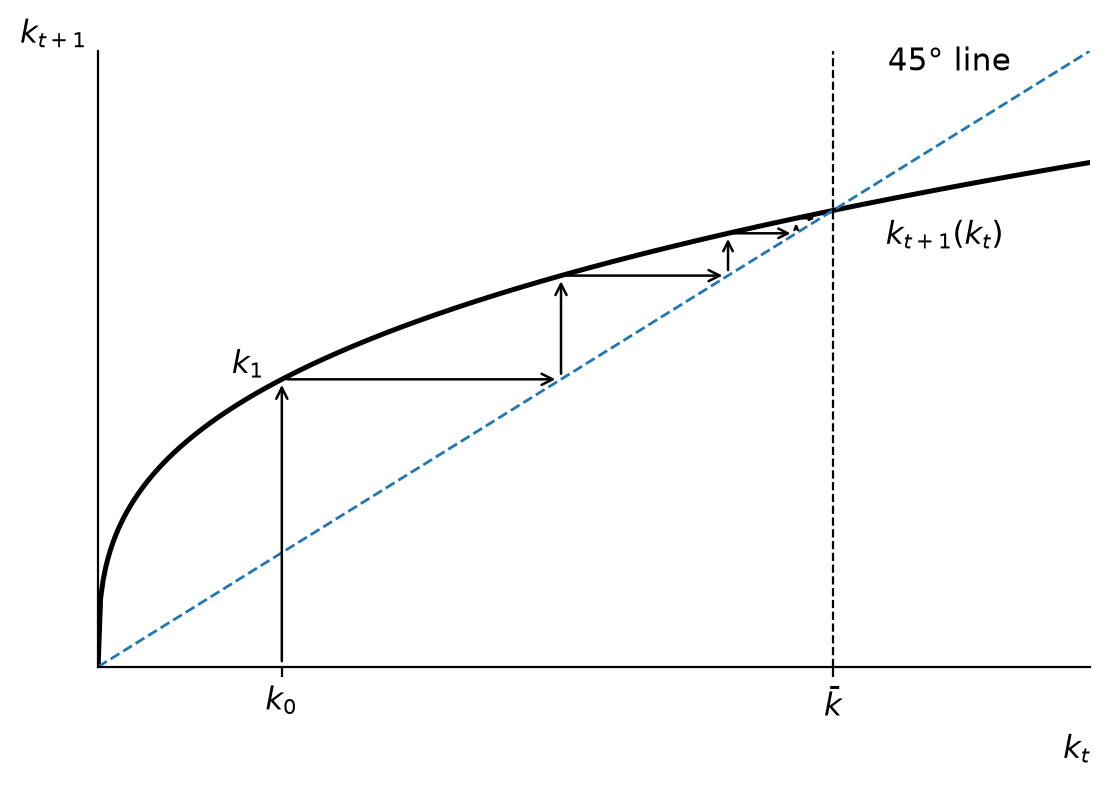

In [ ]:
YEARS = 30
alpha, beta, Xi = 1 / 3, 0.96**YEARS, 1.01**YEARS
kbar = k_bar(alpha, beta, Xi)

fig, ax = plt.subplots()
olg.draw_dynamics(ax, lambda k: k_next(k, alpha, beta, Xi), kbar / 4, kbar)
style.save(fig, "OLGModelDynamics")

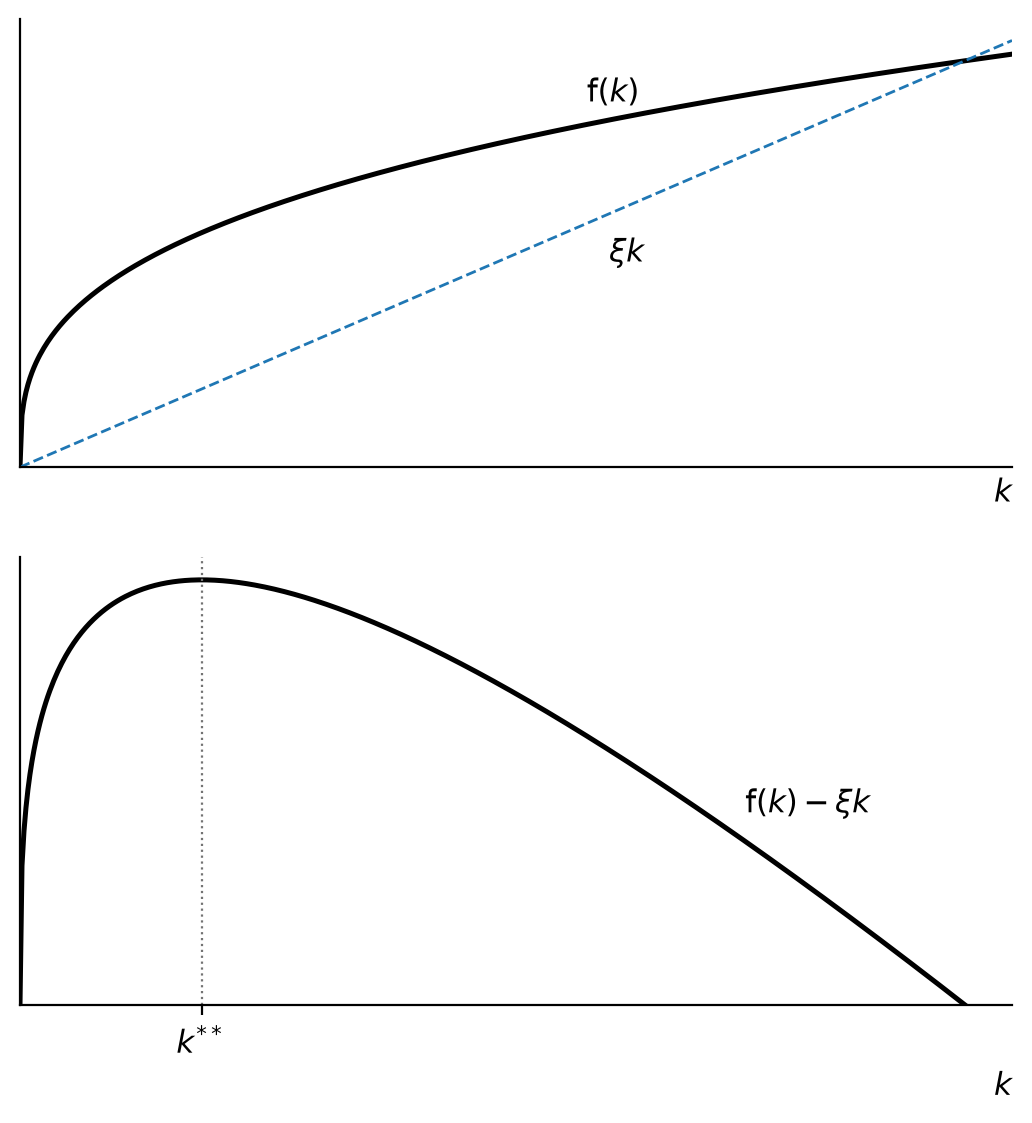

In [ ]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(6.4, 6.4))
olg.draw_output(top, bottom, alpha, Xi - 1, k_golden(alpha, Xi - 1))
style.save(fig, "fnkBoth")

## The chapter's results

In [ ]:
assert np.isclose(k_next(kbar, alpha, beta, Xi), kbar)  # the steady state is a fixed point
k = kbar / 4
for _ in range(60):
    k = k_next(k, alpha, beta, Xi)
assert np.isclose(k, kbar)  # and the economy converges to it
h = 1e-6 * kbar
assert np.isclose((k_next(kbar + h, alpha, beta, Xi) - k_next(kbar - h, alpha, beta, Xi)) / (2 * h), alpha)  # slope alpha at the steady state
kgold = k_golden(alpha, Xi - 1)
assert np.isclose(alpha * kgold ** (alpha - 1), Xi - 1)  # the golden rule: f'(k**) = xi
r = interest_factor(kbar, alpha) - 1
assert np.isclose(r, alpha * Xi * (1 + beta) / ((1 - alpha) * beta))  # the steady-state interest rate in closed form
assert kbar < kgold and r > Xi - 1  # at these values the economy is dynamically efficient: its interest rate exceeds xi
assert round((1 + r) ** (1 / YEARS) - 1, 3) == 0.047  # 4.7 percent a year, against population growth of 1 percent
assert round(kbar / kgold, 2) == 0.04  # and capital is 4 percent of the golden rule's
beth = 0.98**YEARS
assert np.isclose(interest_factor(k_planner(alpha, Xi, beth), alpha), Xi / beth)  # the planner: 1 + f'(k*) = Xi / beth
assert k_planner(alpha, Xi, beth) < kgold  # discounting generations, the planner stops short of the golden rule
kbar1 = k_bar(alpha, beta, 1.0)  # Social Security, with no population growth
for share in (0.05, 0.10, 0.15):
    z = share * wage(kbar1, alpha)
    exact, held = k_bar_payg_exact(alpha, beta, z), k_bar_payg(alpha, beta, z)
    assert np.isclose(k_next_payg_exact(exact, alpha, beta, z), exact)  # a fixed point of the exact curve
    assert held < exact < kbar1  # capital falls, by less than the chapter's figure shows
z = 0.20 * wage(kbar1, alpha)
assert k_bar_payg(alpha, beta, z) is None and k_bar_payg_exact(alpha, beta, z) is not None  # no steady state on the chapter's curve; exactly, one

## With sliders

Each panel redraws on fixed axes, which hold every combination of its sliders' values, so what moves is the economy, not the scale.

Capital per worker: since $\log k_{t+1} = \log \mathcal{Q} + \alpha \log k_{t}$, each generation closes the fraction $1-\alpha$ of the gap, in logs, to the steady state, whatever the other parameters. Patience and population growth move the steady state; the capital share moves the speed as well.

In [ ]:
olg.sliders_dynamics(k_next, k_bar)

Starting in the steady state of the chapter's calibration, something changes: the capital share, patience or population growth from now on, or, once, the number of young, as with a wave of immigration. Capital moves to its new steady state, and the wage and the interest rate with it.

In [ ]:
olg.sliders_transition(k_next, k_bar, wage, interest_factor)

Output, the golden rule and the planner: the economy is dynamically inefficient when $\bar{k}$ exceeds $k^{**}$, that is, when its interest rate is below the rate of population growth, which takes very patient consumers, a low capital share and fast population growth. The planner's $k^{*}$ approaches the golden rule as $\beth$ approaches one. Capital is on a log scale: at the chapter's calibration the economy has a twenty-fifth of the golden rule's capital.

In [ ]:
olg.sliders_output(k_bar, k_golden, k_planner, interest_factor)

Introducing pay-as-you-go [Social Security](https://intertemporal-choice.github.io/content/consumption/socsecandkaccum): the young pay the old a fixed amount, a share of the wage in the old steady state, so they need to save less for retirement, and capital falls from $\bar{k}$ to a lower steady state $\bar{\bar{k}}$. The Social Security chapter's figure holds the interest factor at its old value. In fact it rises as capital falls, which lowers what the old-age benefit is worth today and raises saving, so capital falls by less.

In [ ]:
olg.sliders_payg(k_next, k_bar, wage, k_next_payg, k_bar_payg, k_next_payg_exact, k_bar_payg_exact)